<a href="https://colab.research.google.com/github/malheirosdiogo/Projeto01_AD05_Atendimento_Cliente/blob/main/Desafio2_Estatistica_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Célula 01 - Importações

In [28]:
# ---------- Bibliotecas: ferramentas prontas que o Python usa ----------
import warnings                    # esconde avisos técnicos para não distrair
from pathlib import Path           # manipula caminhos de arquivos e pastas
import shutil                      # manipula arquivos e pastas (ex.: mover, copiar, apagar)

# Estas linhas servem para trabalhar no Google Colab (conectar ao Drive e enviar arquivos)
from google.colab import drive     # conecta o Google Drive ao Colab (para ler e salvar arquivos)
from google.colab import files     # (files) envia arquivos do seu computador para o Colab

# Bibliotecas de análise de dados e de gráficos
import pandas as pd                # tabelas de dados (DataFrame)
import seaborn as sns              # gráficos bonitos e simples
import matplotlib.pyplot as plt    # ajustes nos gráficos (título, linhas...)

# ---------- Configurações gerais (valem para todos os gráficos abaixo) ----------
warnings.filterwarnings("ignore")           # esconde avisos técnicos para não distrair
sns.set_theme(style="whitegrid")            # deixa todos os gráficos com um visual limpo
plt.rcParams["figure.figsize"] = (8, 6)    # tamanho padrão dos gráficos (largura, altura)

# Célula 02 · Carregar os arquivos CSV

In [29]:
# Nomes das tabelas do seu tema (veja a tabela acima), iguais aos nomes dos arquivos CSV.
NOME_TABELA_DIMENSAO = "clientes"   # ex.: "livros"
NOME_TABELA_FATO = "chamados"           # ex.: "emprestimos"

# ---------- 1) Conectando ao Google Drive ----------
drive.mount("/content/drive")      # vai pedir autorização na primeira vez

# ---------- 2) Dizendo onde os arquivos estão guardados ----------
pasta_dados = Path("/content/drive/MyDrive/Colab Notebooks/desafios/dados")   # pasta onde a base fica guardada no Drive
pasta_dados.mkdir(parents=True, exist_ok=True)                                # cria a pasta "dados" se faltar

# O "/" junta a pasta com o nome do arquivo (o nome vem da variável de cada tabela).
caminho_dimensao = pasta_dados / f"{NOME_TABELA_DIMENSAO}.csv"
caminho_fato = pasta_dados / f"{NOME_TABELA_FATO}.csv"

# ---------- 3) Se faltar algum arquivo, envia os dois de uma vez e o código separa ----------
if not caminho_dimensao.exists() or not caminho_fato.exists():
    print(f"Selecione os arquivos CSV ({NOME_TABELA_DIMENSAO} e {NOME_TABELA_FATO}). Pode escolher os dois de uma vez:")
    enviados = files.upload()                                  # abre o seletor; aceita vários arquivos

    for nome_enviado in enviados:                              # percorre cada arquivo enviado
        if NOME_TABELA_DIMENSAO in nome_enviado.lower():       # o nome contém o da dimensão? salva como dimensão
            shutil.move(nome_enviado, caminho_dimensao)        # salva já com o nome da tabela
            print(f"{nome_enviado} -> {caminho_dimensao.name}")
        elif NOME_TABELA_FATO in nome_enviado.lower():         # o nome contém o da fato? salva como fato
            shutil.move(nome_enviado, caminho_fato)
            print(f"{nome_enviado} -> {caminho_fato.name}")
        else:                                                  # nome que não combina com nenhuma tabela
            print(f"Ignorado: {nome_enviado} (o nome não contém '{NOME_TABELA_DIMENSAO}' nem '{NOME_TABELA_FATO}')")

# Confere se os dois arquivos estão no Drive antes de ler.
for caminho in [caminho_dimensao, caminho_fato]:
    if not caminho.exists():
        raise FileNotFoundError(f"Falta o arquivo {caminho.name}. Execute a célula de novo e envie-o.")

# ---------- 4) Lendo os dois arquivos ----------
df_dimensao = pd.read_csv(caminho_dimensao)
df_fato = pd.read_csv(caminho_fato)

print(NOME_TABELA_DIMENSAO, "->", len(df_dimensao), "linhas")
print(NOME_TABELA_FATO, "->", len(df_fato), "linhas")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
clientes -> 10400 linhas
chamados -> 42000 linhas


# Célula 03 · Conhecendo a tabela dimensão

In [30]:
# Quantas linhas (registros do cadastro) e colunas (variáveis) tem a tabela dimensão?
# .shape devolve dois números: (quantidade de linhas, quantidade de colunas)
linhas, colunas = df_dimensao.shape
print(f"A tabela dimensão tem {linhas} linhas e {colunas} colunas (variáveis)")
display(df_dimensao.head())

A tabela dimensão tem 10400 linhas e 4 colunas (variáveis)


,cliente_id,segmento,canal_preferido,data_cadastro
0,1,pequena_empresa,chat,2019-03-01
1,2,pessoa_fisica,chat,2024-04-22
2,3,pessoa_fisica,telefone,2026-05-04
3,4,pequena_empresa,telefone,2025-06-09
4,5,pessoa_fisica,email,2025-06-28


# Célula 04 · Conhecendo a tabela fato

In [31]:
# Quantas linhas (eventos) e colunas (variáveis) tem a tabela fato?
# .shape devolve dois números: (quantidade de linhas, quantidade de colunas)
linhas, colunas = df_fato.shape
print(f"A tabela fato tem {linhas} linhas e {colunas} colunas (variáveis)")
display(df_fato.head())

A tabela fato tem 42000 linhas e 8 colunas (variáveis)


,chamado_id,cliente_id,data_hora_abertura,canal,motivo,tempo_atendimento_min,nota_satisfacao,resolvido_primeiro_contato
0,1,1180,2026-05-08 06:25:57,chat,solicitacao_tecnica,17,2,False
1,2,5899,2026-05-21 11:21:58,telefone,duvida,21,2,False
2,3,195,2025-03-16 18:37:14,telefone,reclamacao,43,3,False
3,4,3216,2025-04-09 02:17:26,presencial,solicitacao_tecnica,13,5,True
4,5,5598,2026-07-05 18:46:00,chat,elogio,15,3,True


# Célula 05 · Tipos das colunas

In [32]:
# 1) Tipo de cada coluna e quantidade de valores preenchidos. Compare com o esquema do plano do tema.
df_fato.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42000 entries, 0 to 41999
Data columns (total 8 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   chamado_id                  42000 non-null  int64 
 1   cliente_id                  42000 non-null  int64 
 2   data_hora_abertura          42000 non-null  object
 3   canal                       42000 non-null  object
 4   motivo                      42000 non-null  object
 5   tempo_atendimento_min       42000 non-null  int64 
 6   nota_satisfacao             42000 non-null  int64 
 7   resolvido_primeiro_contato  42000 non-null  bool  
dtypes: bool(1), int64(4), object(3)
memory usage: 2.3+ MB


# Célula 06 · Valores ausentes

In [33]:
# 2) Valores ausentes por coluna (tabela fato).
print("\nValores ausentes por coluna:")
print(df_fato.isna().sum())


Valores ausentes por coluna:
chamado_id                    0
cliente_id                    0
data_hora_abertura            0
canal                         0
motivo                        0
tempo_atendimento_min         0
nota_satisfacao               0
resolvido_primeiro_contato    0
dtype: int64


# Célula 07 · Linhas duplicadas

In [34]:
# 3) Linhas duplicadas (tabela fato).
print("\nLinhas duplicadas:", df_fato.duplicated().sum())


Linhas duplicadas: 0


# Célula 08 · Chave estrangeira

In [35]:
# 4) Chave estrangeira: todos os registros da tabela fato devem apontar para um ID que existe na tabela dimensão.
COLUNA_FK = "cliente_id"        # ex.: "livro_id" (coluna da fato que referencia a dimensão)
COLUNA_ID = "cliente_id"   # ex.: "livro_id" (coluna de ID da dimensão)
print("\nChaves estrangeiras que batem:", df_fato[COLUNA_FK].isin(df_dimensao[COLUNA_ID]).all())


Chaves estrangeiras que batem: True


**Leitura da conferência**

- A tabela fato (`chamados`) tem 42.000 linhas e nenhuma linha duplicada.
- A chave estrangeira bate: todos os `cliente_id` de `chamados` existem em `clientes` (10.400 clientes).
- A coluna de análise, `tempo_atendimento_min`, não tem valores ausentes e já chegou como número inteiro.
- Nenhuma outra coluna da fato tem valores ausentes, então não há o que explicar sobre campos vazios.

# Célula 09 · Checar a coluna numérica

In [36]:
# Coluna numérica escolhida no Passo 1 (nome EXATO, como está no esquema do tema).
COLUNA_NUMERICA = "tempo_atendimento_min"

# A coluna escolhida, como uma série (uma coluna do DataFrame).
serie_numerica = df_fato[COLUNA_NUMERICA]
print("Valores preenchidos:", serie_numerica.count(), "| ausentes:", serie_numerica.isna().sum())

Valores preenchidos: 42000 | ausentes: 0


# Célula 10 · Medidas estatísticas

In [37]:
# Medidas de Tendência central e dispersão.
medidas = pd.Series({
    "Média": serie_numerica.mean(),
    "Mediana": serie_numerica.median(),
    "Moda": serie_numerica.mode()[0],            # se houver empate, a primeira será selecionada
    "Desvio padrão": serie_numerica.std(),
    "Variância": serie_numerica.var(),
    "Mínimo": serie_numerica.min(),
    "Máximo": serie_numerica.max(),
    "Amplitude": serie_numerica.max() - serie_numerica.min(),
}).round(2)
display(medidas)

# Média muito diferente da mediana é sinal de valores extremos ou de dados assimétricos.
print("Média - mediana:", round(medidas["Média"] - medidas["Mediana"], 2))

,0
Média,15.60
Mediana,13.00
Moda,9.00
Desvio padrão,11.28
Variância,127.24
Mínimo,1.00
Máximo,107.00
Amplitude,106.00


Média - mediana: 2.6


## Passo 6 · Frases de insight

- **A média de `tempo_atendimento_min` é 15,60 minutos**. É o tempo médio de um chamado, mas ela é puxada para cima pelos atendimentos muito longos, e por isso não representa o chamado típico.

- **A mediana de `tempo_atendimento_min` é 13,00 minutos**. Metade dos chamados termina em 13 minutos ou menos. Ela fica 2,60 minutos abaixo da média, o que mostra que poucos atendimentos longos (o maior chega a 107 minutos) elevam a média.

- **O desvio padrão de `tempo_atendimento_min` é 11,28 minutos**. É cerca de 72% da média de 15,60, ou seja, a variação é grande: há chamados de 1 minuto e de mais de 90, e o tempo de um chamado individual é difícil de prever.

- **Decisão final:** usar a mediana (13 min) como referência do atendimento típico e tratar à parte os chamados muito longos, em vez de usar a média como meta.

# Célula 11 · Juntar a fato com a dimensão

In [38]:
# Junta a fato com a dimensão: cada registro da fato recebe as colunas do seu cadastro.
df_completo = df_fato.merge(df_dimensao, left_on=COLUNA_FK, right_on=COLUNA_ID, how="left", suffixes=("", "_dim"))

print("Linhas da fato:", len(df_fato), "| depois da junção:", len(df_completo))   # precisam ser iguais

Linhas da fato: 42000 | depois da junção: 42000


In [39]:
df_completo.head()

,chamado_id,cliente_id,data_hora_abertura,canal,motivo,tempo_atendimento_min,nota_satisfacao,resolvido_primeiro_contato,segmento,canal_preferido,data_cadastro
0,1,1180,2026-05-08 06:25:57,chat,solicitacao_tecnica,17,2,False,pessoa_fisica,email,2024-12-30
1,2,5899,2026-05-21 11:21:58,telefone,duvida,21,2,False,grande_empresa,chat,2022-09-12
2,3,195,2025-03-16 18:37:14,telefone,reclamacao,43,3,False,pessoa_fisica,email,2021-11-22
3,4,3216,2025-04-09 02:17:26,presencial,solicitacao_tecnica,13,5,True,pessoa_fisica,email,2022-03-10
4,5,5598,2026-07-05 18:46:00,chat,elogio,15,3,True,pessoa_fisica,telefone,2020-10-03


# Célula 12 · Comparar grupos por uma coluna da fato

In [40]:
# Coluna categórica usada para comparar (da fato ou da dimensão). Poucos valores diferentes funcionam melhor.
COLUNA_GRUPO = "canal"

# Quantidade, média, mediana e desvio padrão de cada grupo, do maior para o menor valor médio.
por_grupo = df_completo.groupby(COLUNA_GRUPO)[COLUNA_NUMERICA].agg(["count", "mean", "median", "std"]).round(2)
por_grupo = por_grupo.sort_values("mean", ascending=False)
display(por_grupo)

,count,mean,median,std
canal,,,,
telefone,12615,15.70,13.0,11.38
presencial,4131,15.65,13.0,11.19
chat,14762,15.63,13.0,11.32
email,10492,15.42,13.0,11.14


**Leitura por canal**

- O telefone tem a maior média (15,70 min), mas a diferença para o menor, o e-mail (15,42 min), é de apenas 0,28 minuto. A mediana é 13 em todos os canais, então ela confirma que não há diferença real.
- O telefone também tem o maior desvio padrão (11,38), mas a diferença para os outros canais (11,14 a 11,32) é pequena.
- Com médias, medianas e desvios quase iguais, o canal não explica o tempo de atendimento.

# Célula 13 · Comparar grupos por uma coluna da dimensão

In [41]:
COLUNA_GRUPO = "segmento"     # coluna da dimensão: só existe em df_completo por causa da junção

# Quantidade, média, mediana e desvio padrão de cada grupo, do maior para o menor valor médio.
por_grupo = df_completo.groupby(COLUNA_GRUPO)[COLUNA_NUMERICA].agg(["count", "mean", "median", "std"]).round(2)
por_grupo = por_grupo.sort_values("mean", ascending=False)
display(por_grupo)

,count,mean,median,std
segmento,,,,
grande_empresa,2066,15.70,13.0,11.56
pessoa_fisica,31534,15.62,13.0,11.29
pequena_empresa,8400,15.53,13.0,11.18


**Leitura por segmento**

- A grande empresa tem a maior média (15,70 min), mas a diferença para a pequena empresa (15,53) é de 0,17 minuto, e a mediana é 13 nos três segmentos.
- A grande empresa também tem o maior desvio padrão (11,56), com os valores mais espalhados, mas é o grupo com menos registros (2.066), então a leitura pede cautela.
- Os segmentos têm médias quase iguais, o que também é um resultado: o segmento do cliente não explica o tempo de atendimento.

## Passo 8 · Ausentes e outliers
### Célula 14 · Regra do IQR

In [42]:
# Faixa central dos dados: do 1º ao 3º quartil (25% e 75%).
q1 = serie_numerica.quantile(0.25)
q3 = serie_numerica.quantile(0.75)
iqr = q3 - q1

# Regra usual: fora de [Q1 - 1,5 x IQR ; Q3 + 1,5 x IQR] é candidato a outlier.
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

# Cálculo do número de outliers
sem_outliers = serie_numerica[(serie_numerica >= limite_inferior) & (serie_numerica <= limite_superior)]
qtd_outliers = serie_numerica.count() - sem_outliers.count()

print(f"Limites: {limite_inferior:.2f} a {limite_superior:.2f}")
print(f"Outliers: {qtd_outliers} de {serie_numerica.count()} valores")
print("Maiores valores:", serie_numerica.nlargest(5).tolist())
print("Menores valores:", serie_numerica.nsmallest(5).tolist())

Limites: -14.00 a 42.00
Outliers: 1247 de 42000 valores
Maiores valores: [107, 96, 96, 95, 93]
Menores valores: [1, 1, 1, 1, 1]


### Célula 15 · Medidas com e sem os candidatos a outlier

In [43]:
# Compara as medidas com e sem os candidatos a outlier.
comparacao = pd.DataFrame({
    "Com outliers": [serie_numerica.mean(), serie_numerica.median(), serie_numerica.std()],
    "Sem outliers": [sem_outliers.mean(), sem_outliers.median(), sem_outliers.std()],
}, index=["Média", "Mediana", "Desvio padrão"]).round(2)
display(comparacao)

,Com outliers,Sem outliers
Média,15.60,14.50
Mediana,13.00,13.00
Desvio padrão,11.28,9.38


**Leitura e decisão registrada**

- (quantos valores a regra do IQR marcou, a partir de que valor, e como as medidas mudam sem eles)
- **Decisão:** (manter, tratar ou excluir) e o porquê
- **Valores ausentes:** (o que foi feito com eles e por quê)

- A regra do IQR marcou 1.247 de 42.000 chamados (cerca de 3%), todos acima de 42 minutos. Sem eles, a média cai de 15,60 para 14,50, o desvio padrão cai de 11,28 para 9,38 e a mediana continua em 13,00.
- **Decisão:** manter. Os maiores valores (107, 96, 96, 95 e 93 minutos) são plausíveis para um atendimento complexo, não há valor negativo ou impossível (o mínimo é 1 minuto) e eles não parecem erro de preenchimento. Os valores de 42 minutos para cima são o resultado de interesse da análise, não ruído a ser apagado.
- **Valores ausentes:** não há ausentes em nenhuma coluna da fato (Célula 06), então nada foi preenchido nem removido.

## Passo 9 · Distribuição
### Célula 16 · Assimetria (skew)

In [44]:
# Assimetria: perto de 0 = formato equilibrado; positiva = cauda para valores altos; negativa = para valores baixos.
print("Assimetria:", round(serie_numerica.skew(), 2))

Assimetria: 1.39


### Célula 17 · Percentis


In [45]:
# Percentis: por exemplo, 50% dos valores ficam na mediana ou abaixo dela.
print(serie_numerica.quantile([0.10, 0.25, 0.50, 0.75, 0.90]))

0.10     4.0
0.25     7.0
0.50    13.0
0.75    21.0
0.90    31.0
Name: tempo_atendimento_min, dtype: float64


### Célula 18 · Quantidade de valores por faixa


In [46]:
# Quantidade de valores em 5 faixas de mesmo tamanho (a versão em texto de um histograma).
display(pd.cut(serie_numerica, bins=5).value_counts().sort_index())

,count
tempo_atendimento_min,
"(0.894, 22.2]",32710
"(22.2, 43.4]",8169
"(43.4, 64.6]",1018
"(64.6, 85.8]",92
"(85.8, 107.0]",11


**Leitura da distribuição**

- A assimetria é 1,39, positiva: há uma cauda longa para os valores altos, o que combina com a média (15,60) maior que a mediana (13,00).
- Até 21 minutos ficam 75% dos chamados e até 31 minutos ficam 90%.
- A primeira faixa (de 1 a 22 minutos) concentra 32.710 chamados, cerca de 78% do total, e as duas faixas mais altas (acima de 64,6 minutos) somam só 103 chamados.
- Em palavras: a maioria dos chamados dura entre 7 e 21 minutos, e poucos passam de 42.

## Passo 10

## Recomendação

**Pergunta de negócio:** o tempo de atendimento muda o suficiente entre canais e segmentos para justificar metas de tempo diferentes para cada um?

**Evidência 1:** a média por canal vai de 15,42 (e-mail) a 15,70 minutos (telefone) e a mediana é 13 em todos. Por segmento, a média vai de 15,53 a 15,70. Canal e segmento quase não mudam o tempo de atendimento.

**Evidência 2:** o desvio padrão geral é 11,28 minutos (cerca de 72% da média de 15,60) e 1.247 chamados (cerca de 3%) passam de 42 minutos. A variação está dentro de cada grupo, nos atendimentos muito longos, e não entre os grupos.

**Recomendação em uma frase:** usar uma meta única para todos os canais e segmentos, baseada na mediana de 13 minutos e no percentil 90 de 31 minutos, e investigar os chamados acima de 42 minutos, que é onde está a variação.

**Limites da análise:** os dados são fictícios e a base não tem informação sobre a complexidade de cada chamado. Os 1.247 valores marcados pela regra do IQR foram mantidos por serem plausíveis, e não havia valores ausentes.

## Passo 11 · Gráficos
### Célula 19 · Histograma

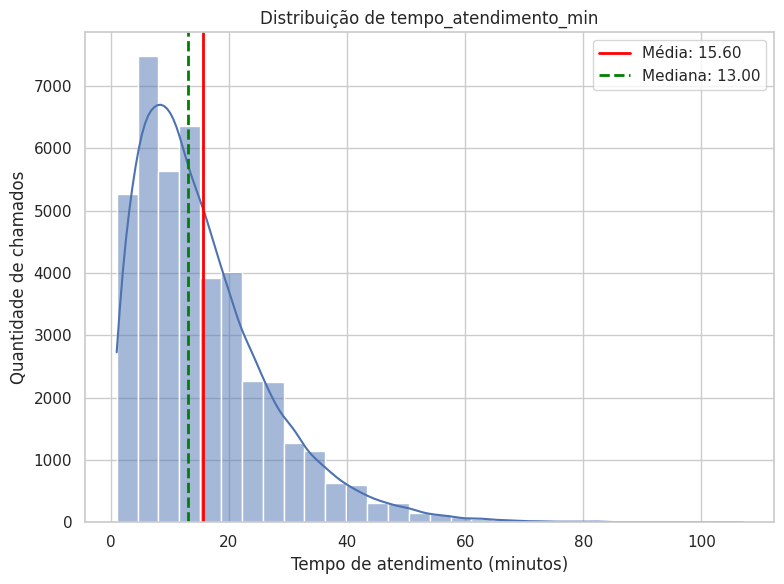

In [47]:
# Generated-by: AI (Claude)
# AI-Generated-Date: 2026-11-16
# SPDX-SnippetCopyrightText: AI-Assisted Code
# SPDX-License-Identifier: MIT

# Histograma: como os valores se distribuem, com a curva da distribuição e as linhas de média e mediana.
sns.histplot(serie_numerica.dropna(), bins=30, kde=True)
plt.axvline(serie_numerica.mean(), color="red", linestyle="-", linewidth=2, label=f"Média: {serie_numerica.mean():.2f}")
plt.axvline(serie_numerica.median(), color="green", linestyle="--", linewidth=2, label=f"Mediana: {serie_numerica.median():.2f}")
plt.title(f"Distribuição de {COLUNA_NUMERICA}")
plt.xlabel("Tempo de atendimento (minutos)")
plt.ylabel("Quantidade de chamados")
plt.legend()
plt.tight_layout()
plt.show()

### Célula 20 · Boxplot


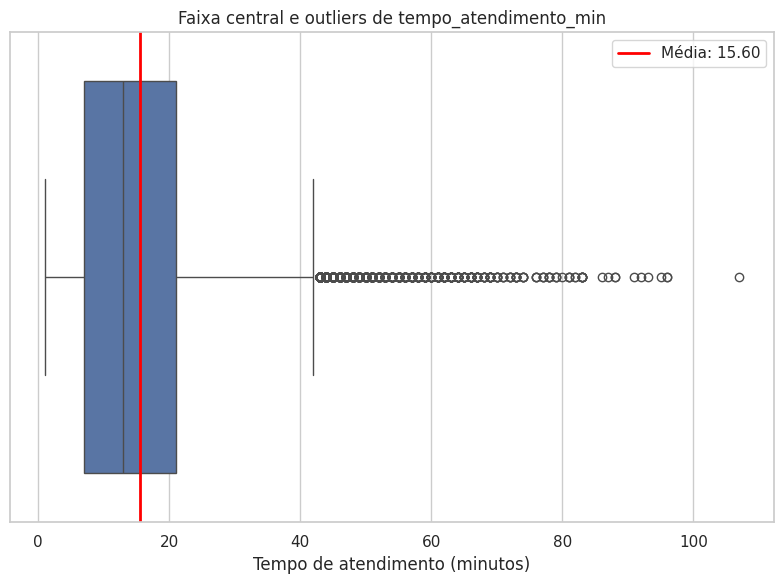

In [48]:
# Generated-by: AI (Claude)
# AI-Generated-Date: 2026-11-16
# SPDX-SnippetCopyrightText: AI-Assisted Code
# SPDX-License-Identifier: MIT

# Boxplot: a caixa é a faixa central (25% a 75%); os pontos fora são candidatos a outlier.
sns.boxplot(x=serie_numerica.dropna())
plt.axvline(serie_numerica.mean(), color="red", linestyle="-", linewidth=2, label=f"Média: {serie_numerica.mean():.2f}")
plt.title(f"Faixa central e outliers de {COLUNA_NUMERICA}")
plt.xlabel("Tempo de atendimento (minutos)")
plt.legend()
plt.tight_layout()
plt.show()